In [10]:
import pandas as pd
import sqlite3
from pandas.plotting import scatter_matrix

In [11]:
conn=sqlite3.connect('../data/checking-logs.sqlite')
test=pd.read_csv('../data/ab-test.csv')
test=test[test['group']=='test'][['uid']]
test=test.groupby('uid').size().reset_index(name='counts')
test=test['uid'].reset_index(name='uid')
test

,index,uid
0,0,user_1
1,1,user_18
2,2,user_19
3,3,user_21
4,4,user_25
5,5,user_28
6,6,user_3


In [12]:
checker=pd.read_sql("select * from checker where uid like 'user_%' and labname not like 'project1' ", conn)
pageviews=pd.read_sql("select * from pageviews where uid like 'user_%'", conn)
deadlines=pd.read_sql("select * from deadlines where labs not like 'project1'", conn)

In [13]:
pageviews_cnt=pageviews.groupby('uid').size().reset_index(name='views')
pageviews_cnt

,uid,views
0,user_1,28
1,user_10,89
2,user_14,143
3,user_17,47
4,user_18,3
5,user_19,16
6,user_21,10
7,user_25,179
8,user_28,149
9,user_3,317


In [14]:
commits_cnt=checker.groupby('uid').size().reset_index(name='commits')
commits_cnt

,uid,commits
0,user_0,3
1,user_1,62
2,user_10,20
3,user_11,7
4,user_12,86
5,user_13,52
6,user_14,61
7,user_15,23
8,user_16,41
9,user_17,51


In [15]:
diffs=checker.merge(right=deadlines,left_on='labname',right_on='labs',how='left')
diffs
diffs['timestamp']=pd.to_datetime(diffs['timestamp']).apply(lambda x: x.timestamp())
diffs['diffs']=diffs['timestamp']-diffs['deadlines']

In [16]:
diffs=diffs[['uid','diffs']]
diffs=diffs.groupby('uid').mean()
diffs['diffs']=diffs['diffs']/3600

In [17]:
df=pd.DataFrame(test['uid'])
df=df.merge(right=diffs,on='uid',how='left')
df=df.merge(right=pageviews_cnt,on='uid',how='left')
df=df.merge(right=commits_cnt,on='uid',how='left')
df

,uid,diffs,views,commits
0,user_1,-58.634224,28,62
1,user_18,-5.381577,3,5
2,user_19,-47.333223,16,118
3,user_21,-84.473952,10,65
4,user_25,-47.024429,179,79
5,user_28,-40.825128,149,60
6,user_3,-105.375341,317,18


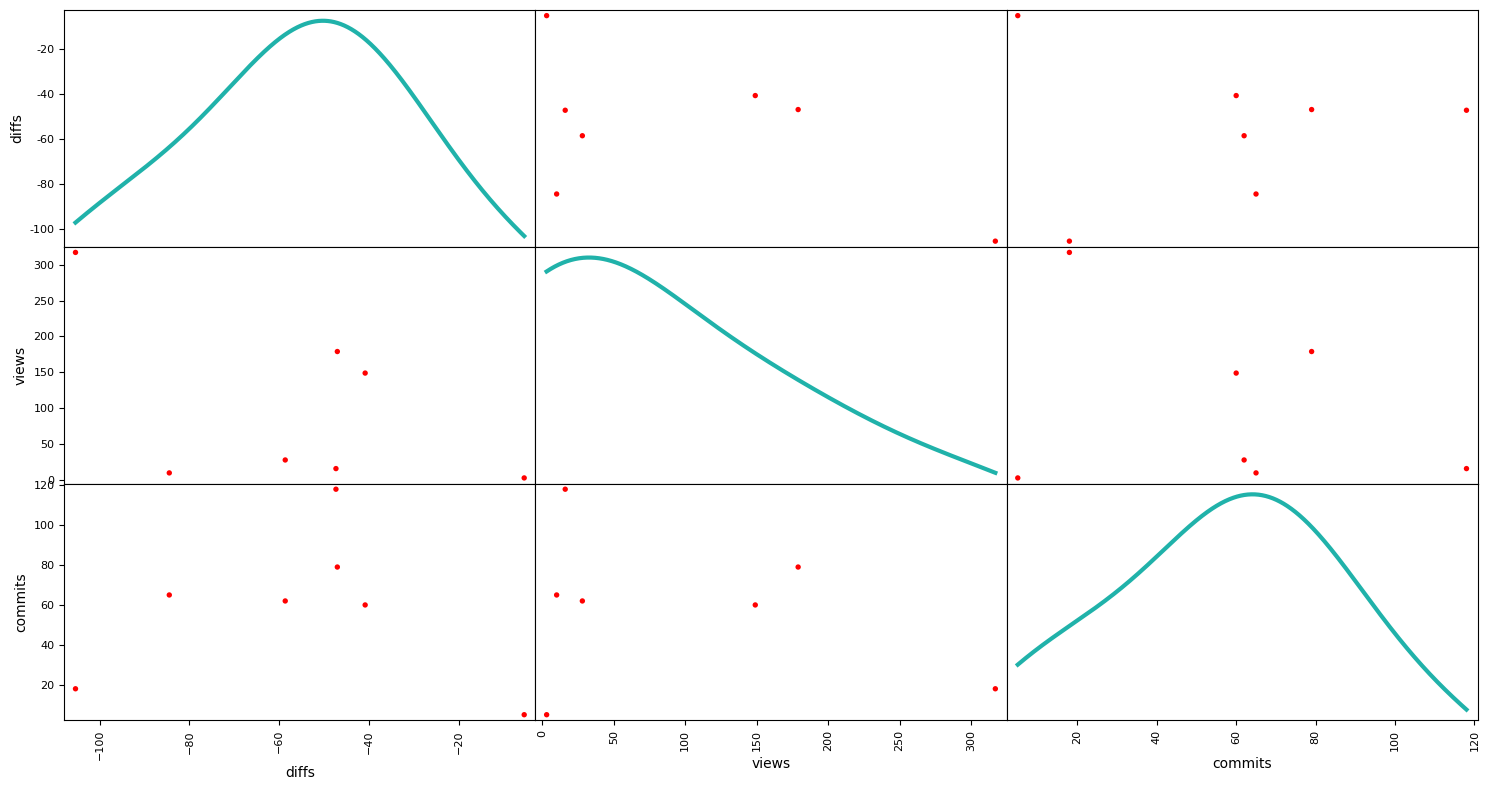

In [18]:
import matplotlib.pyplot as plt
ax = scatter_matrix(df[['diffs', 'views', 'commits']], 
                    figsize=(15, 8), 
                    diagonal='kde', 
                    density_kwds={'color': '#20B2AA', 'linewidth': 3}, 
                    s=60, 
                    color='red', 
                    alpha=1)

for axis in ax.flatten():
    axis.grid(False)
    
    axis.xaxis.label.set_fontsize(10)
    axis.yaxis.label.set_fontsize(10)

plt.tight_layout()
plt.subplots_adjust(wspace=0, hspace=0)
plt.show()

Can we say that if a user has a low number of pageviews, then they likely have a low number of commits?

No

Can we say that if a user has a low number of pageviews, then they likely have a small average difference between the first commit and the lab deadline?

Yes

Can we say that there are many users with a low number of commits and a few with a high number of commits?

Yes

Can we say that there are many users with a small average difference and a few with a large average difference?

No